# BhumiGuard BD — STEP 2: Dataset Audit

This notebook audits the raw source data before any preprocessing or OCR.

Checks:
- deed and supporting-form file types
- handwritten image count
- corrupted/unreadable images
- image dimensions
- image modes

No raw file is modified.

In [1]:
from pathlib import Path

cwd = Path.cwd().resolve()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

DEED_DIR = PROJECT_ROOT / "data/raw/deed_samples"
HANDWRITTEN_DIR = PROJECT_ROOT / "data/raw/handwritten_dolil"
SUPPORTING_DIR = PROJECT_ROOT / "data/raw/supporting_forms"
DLRS_DIR = PROJECT_ROOT / "data/raw/dlrs_forms"

print("Project root:", PROJECT_ROOT)

Project root: D:\BhumiGuard-BD


In [2]:
from collections import Counter

def get_files(folder):
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.name != ".gitkeep"
    ]

deed_files = get_files(DEED_DIR)
supporting_files = get_files(SUPPORTING_DIR)
dlrs_files = get_files(DLRS_DIR)

deed_ext = Counter(p.suffix.lower() for p in deed_files)
supporting_ext = Counter(p.suffix.lower() for p in supporting_files)
dlrs_ext = Counter(p.suffix.lower() for p in dlrs_files)

print("Deed files:", len(deed_files))
print("Deed extensions:", dict(deed_ext))

print("\nSupporting files:", len(supporting_files))
print("Supporting extensions:", dict(supporting_ext))

print("\nDLRS files:", len(dlrs_files))
print("DLRS extensions:", dict(dlrs_ext))

Deed files: 17
Deed extensions: {'.docx': 2, '.pdf': 15}

Supporting files: 5
Supporting extensions: {'.docx': 4, '.pdf': 1}

DLRS files: 0
DLRS extensions: {}


## Handwritten Image Integrity Check

Check whether all 653 JPG images can be opened successfully.

In [6]:
%pip install pillow

  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl (7.2 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from PIL import Image

image_files = [
    p for p in HANDWRITTEN_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

corrupted = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as e:
        corrupted.append((path.name, str(e)))

print("Total images:", len(image_files))
print("Readable images:", len(image_files) - len(corrupted))
print("Corrupted images:", len(corrupted))

if corrupted:
    for item in corrupted[:10]:
        print(item)

Total images: 653
Readable images: 653
Corrupted images: 0


## STEP 2C — Image Dimension and Color Mode Audit

Check image resolution variation and image color modes without modifying any raw image.

In [8]:
from collections import Counter

sizes = []
modes = []

for path in image_files:
    with Image.open(path) as img:
        sizes.append(img.size)
        modes.append(img.mode)

widths = [w for w, h in sizes]
heights = [h for w, h in sizes]

print("Images inspected:", len(sizes))

print("\nWidth:")
print("Min:", min(widths))
print("Max:", max(widths))

print("\nHeight:")
print("Min:", min(heights))
print("Max:", max(heights))

print("\nImage modes:")
print(dict(Counter(modes)))

Images inspected: 653

Width:
Min: 720
Max: 4608

Height:
Min: 1280
Max: 4608

Image modes:
{'RGB': 653}


## STEP 2D — Unique Image Size Distribution

Check how many different image resolutions exist and identify the most common resolutions.

In [9]:
size_counts = Counter(sizes)

print("Unique image sizes:", len(size_counts))

print("\n10 most common sizes:")
for size, count in size_counts.most_common(10):
    print(size, "->", count)

Unique image sizes: 54

10 most common sizes:
(4000, 3000) -> 402
(3456, 4608) -> 58
(4608, 3456) -> 48
(4160, 3120) -> 41
(720, 1280) -> 39
(3120, 4160) -> 13
(900, 1600) -> 5
(1768, 2768) -> 1
(1892, 3008) -> 1
(1748, 2800) -> 1


## STEP 2E — Exact Duplicate Detection

Detect exact duplicate images using SHA-256 file hashes.

No image is modified or deleted.

In [10]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for path in image_files:
    with open(path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    hash_groups[file_hash].append(path.name)

duplicate_groups = {
    h: names
    for h, names in hash_groups.items()
    if len(names) > 1
}

duplicate_file_count = sum(
    len(names) - 1
    for names in duplicate_groups.values()
)

print("Total images:", len(image_files))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_file_count)

Total images: 653
Unique file hashes: 653
Duplicate groups: 0
Extra duplicate files: 0


## STEP 2F — Orientation and Aspect Ratio Audit

Check how many handwritten document images are portrait, landscape, or square.

No image is modified.

In [11]:
portrait = 0
landscape = 0
square = 0
aspect_ratios = []

for width, height in sizes:
    ratio = width / height
    aspect_ratios.append(ratio)

    if width < height:
        portrait += 1
    elif width > height:
        landscape += 1
    else:
        square += 1

print("Portrait images:", portrait)
print("Landscape images:", landscape)
print("Square images:", square)

print("\nAspect ratio:")
print("Min:", round(min(aspect_ratios), 3))
print("Max:", round(max(aspect_ratios), 3))

Portrait images: 161
Landscape images: 492
Square images: 0

Aspect ratio:
Min: 0.45
Max: 1.585


In [12]:
total = len(sizes)

print("Portrait %:", round(portrait / total * 100, 2))
print("Landscape %:", round(landscape / total * 100, 2))
print("Square %:", round(square / total * 100, 2))

Portrait %: 24.66
Landscape %: 75.34
Square %: 0.0


## STEP 2G — File Size Audit

Check image file-size distribution to identify unusually small or large files.

No file is modified.

In [13]:
file_sizes_kb = []

for path in image_files:
    size_kb = path.stat().st_size / 1024
    file_sizes_kb.append((path.name, size_kb))

sizes_only = [size for _, size in file_sizes_kb]

print("Image files:", len(file_sizes_kb))
print("Minimum size (KB):", round(min(sizes_only), 2))
print("Maximum size (KB):", round(max(sizes_only), 2))
print("Average size (KB):", round(sum(sizes_only) / len(sizes_only), 2))

Image files: 653
Minimum size (KB): 43.02
Maximum size (KB): 5919.89
Average size (KB): 3478.29


In [14]:
small_files = [
    (name, size)
    for name, size in file_sizes_kb
    if size < 50
]

print("Files smaller than 50 KB:", len(small_files))

for name, size in small_files[:20]:
    print(name, "->", round(size, 2), "KB")

Files smaller than 50 KB: 2
dolil_445.jpg -> 43.02 KB
dolil_453.jpg -> 46.31 KB


In [15]:
smallest_10 = sorted(file_sizes_kb, key=lambda x: x[1])[:10]

print("10 smallest files:")
for name, size in smallest_10:
    print(name, "->", round(size, 2), "KB")

10 smallest files:
dolil_445.jpg -> 43.02 KB
dolil_453.jpg -> 46.31 KB
dolil_439.jpg -> 52.75 KB
dolil_434.jpg -> 57.12 KB
dolil_313.jpg -> 57.27 KB
dolil_441.jpg -> 57.87 KB
dolil_449.jpg -> 59.27 KB
dolil_462.jpg -> 60.96 KB
dolil_442.jpg -> 61.07 KB
dolil_443.jpg -> 61.25 KB


## STEP 2H — Visual Quality Inspection

Inspect low-size and random handwritten Dolil images for:
- blur
- skew/rotation
- lighting
- cropping
- handwriting visibility
- background noise

In [17]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 3.4 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.3 MB 2.6 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.3 MB 2.6 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.3 MB 2.6 MB/s eta 0:00:04
   ----------- ---------------------------- 2.6/9.3 MB 2.2 MB/s eta 0:00:04
   ------------ --------------------------- 2.9/9.3 MB 2.0 MB/s eta 0:00:04
   -------------- ------------------------- 3.4/9.3 MB 2.1 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 2.1 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.3 MB 2.0 MB/s eta 0:00:03
   ------------------- -------------------- 4.5/9.3 MB 2.0 MB/s eta 0:00:03
   --------------------- ------------------ 5.0/9.3 MB 2.0 MB/s eta 0:00:03
   ---------------------- 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


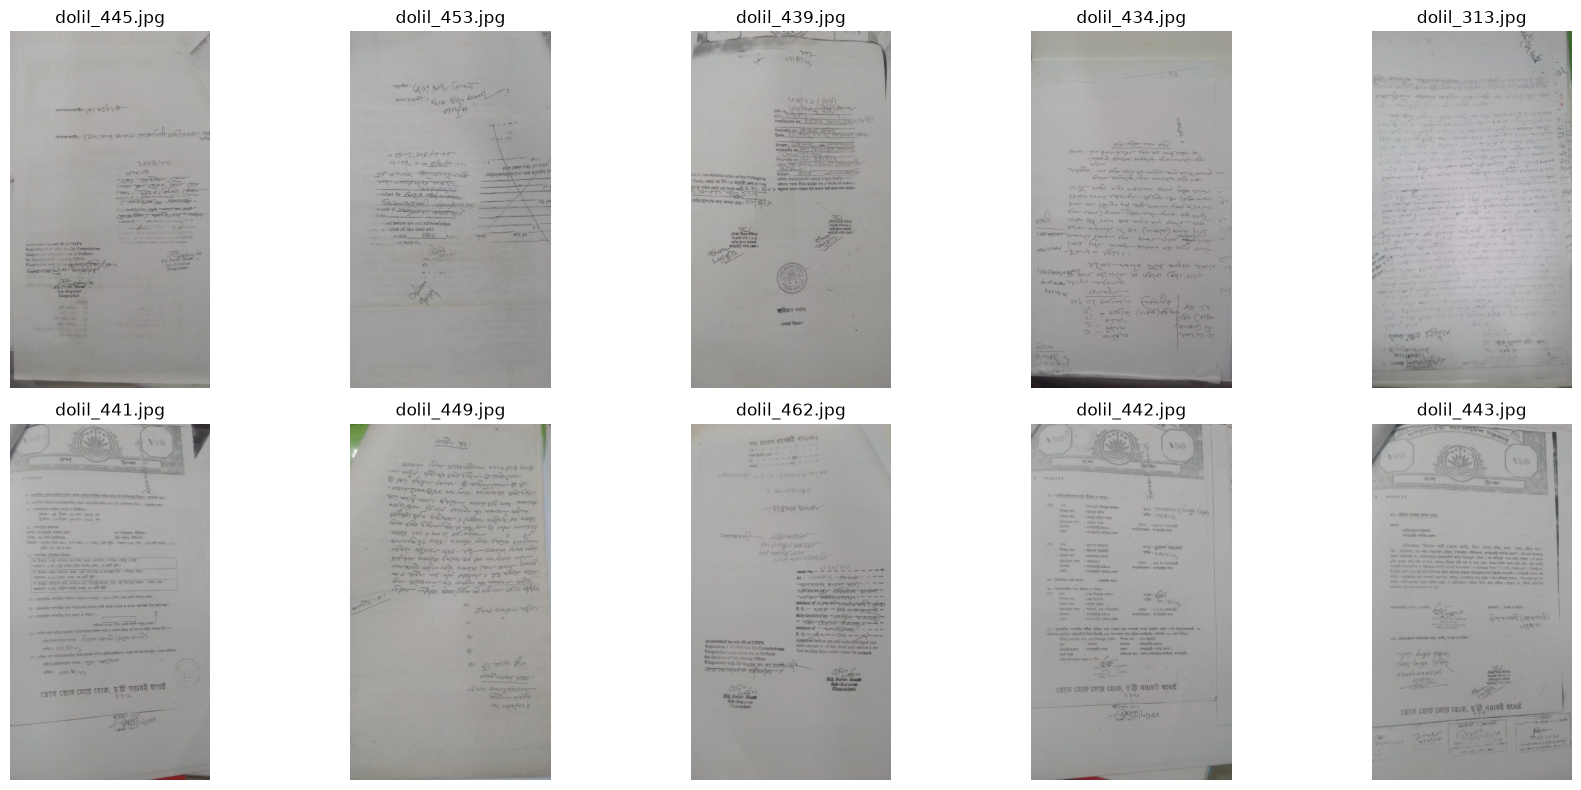

In [18]:
import matplotlib.pyplot as plt

smallest_paths = [
    HANDWRITTEN_DIR / name
    for name, _ in smallest_10
]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, path in zip(axes.ravel(), smallest_paths):
    with Image.open(path) as img:
        ax.imshow(img)
        ax.set_title(path.name)
        ax.axis("off")

plt.tight_layout()
plt.show()

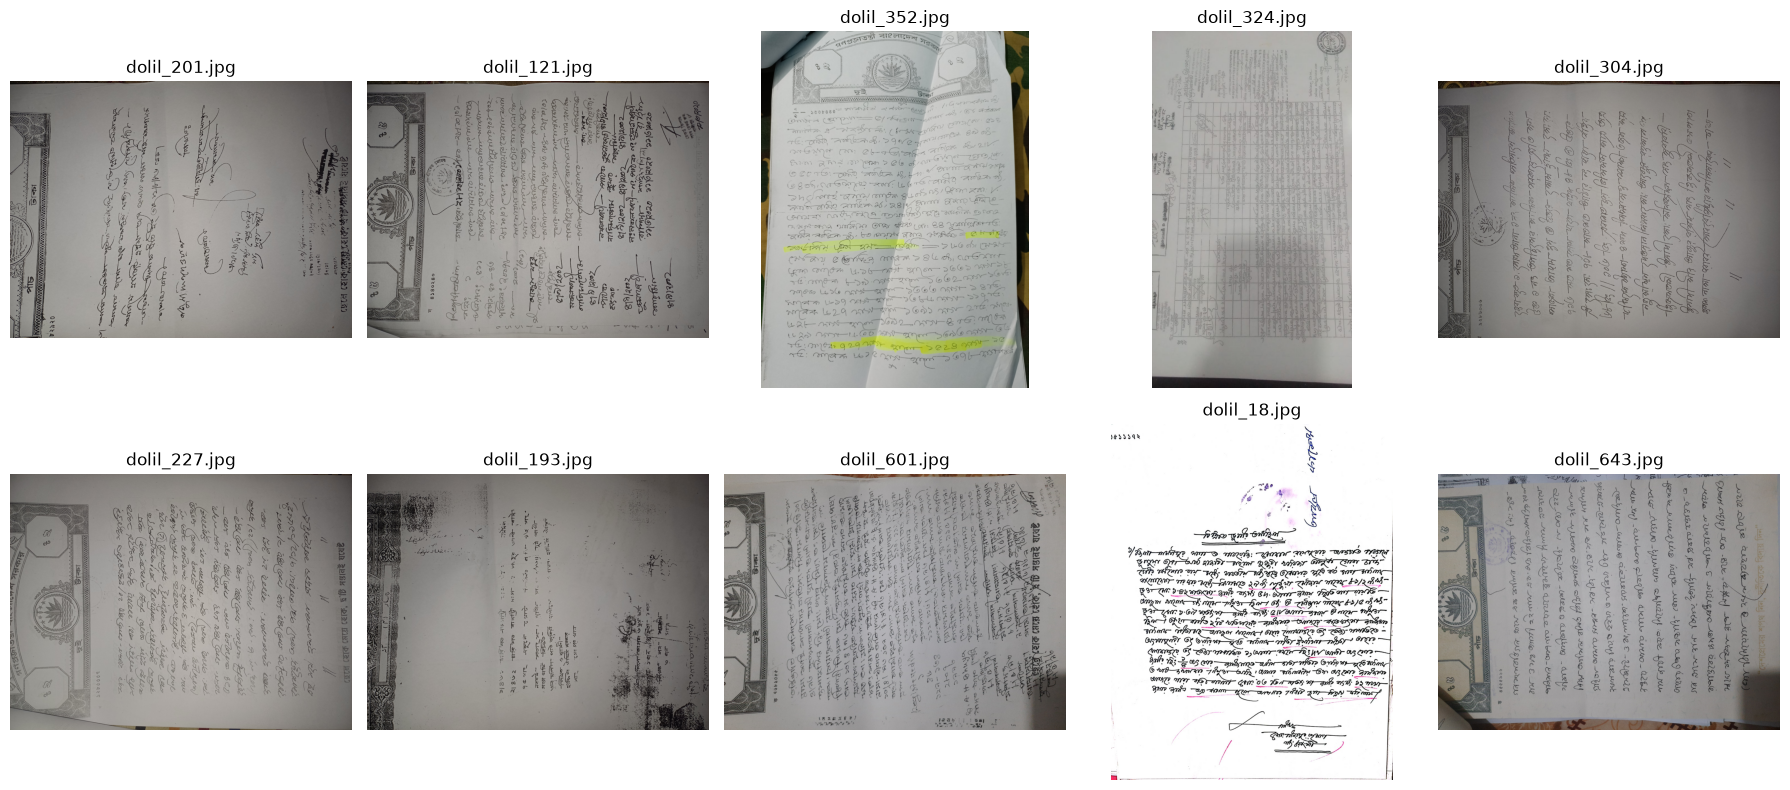

In [19]:
import random

random.seed(42)

random_paths = random.sample(image_files, 10)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, path in zip(axes.ravel(), random_paths):
    with Image.open(path) as img:
        ax.imshow(img)
        ax.set_title(path.name)
        ax.axis("off")

plt.tight_layout()
plt.show()

## STEP 2I — Dataset Audit Findings

The raw handwritten Dolil dataset contains 653 JPG images.

### Integrity
- Total images: 653
- Readable images: 653
- Corrupted images: 0
- Exact duplicate groups: 0

### Image characteristics
- RGB images: 653
- Unique image resolutions: 54
- Width range: 720–4608 pixels
- Height range: 1280–4608 pixels
- Most common resolution: 4000×3000
- Portrait: 161 (24.66%)
- Landscape: 492 (75.34%)

### File-size characteristics
- Minimum: 43.02 KB
- Maximum: 5919.89 KB
- Average: 3478.29 KB
- Files below 50 KB: 2

### Visual-quality findings
The dataset contains substantial real-world variation:
- rotated/sideways document photographs
- low-contrast and faded pages
- uneven lighting and shadows
- perspective/skew
- mixed handwritten and printed Bengali text
- stamps, seals, signatures and highlighted text
- different camera resolutions
- variable page framing and background regions

No raw image will be deleted or modified.
These variations will be handled during the OCR preprocessing stage.

In [20]:
print("STEP 2 FINAL STATUS")
print("-------------------")
print("Handwritten images:", len(image_files))
print("Readable:", len(image_files) - len(corrupted))
print("Corrupted:", len(corrupted))
print("Exact duplicates:", duplicate_file_count)
print("Unique resolutions:", len(size_counts))
print("RGB images:", modes.count("RGB"))
print("Portrait:", portrait)
print("Landscape:", landscape)

print("\nDATASET AUDIT: PASS")
print("Raw dataset preserved without modification.")

STEP 2 FINAL STATUS
-------------------
Handwritten images: 653
Readable: 653
Corrupted: 0
Exact duplicates: 0
Unique resolutions: 54
RGB images: 653
Portrait: 161
Landscape: 492

DATASET AUDIT: PASS
Raw dataset preserved without modification.
